## Exercise 1: Time-Series Anomaly Detection using LSTM-VAE

### Objective
The objective of this lab is to implement an LSTM Variational Autoencoder (VAE). Unlike standard Autoencoders that map input to a fixed vector, a VAE maps input to a probability distribution (Gaussian). This implementation specifically uses Long Short-Term Memory (LSTM) layers to capture temporal dependencies in multi-dimensional sensor data.

### Key Concepts: 
* **Encoder:** Compresses a window of time-series data into a mean ($\mu$) and variance ($\sigma$).
* **Latent Space:** A 100-dimensional space representing the underlying "rules" or patterns of the signal.
* **Reparameterization Trick:** A method to allow backpropagation through random sampling by using the formula:
      $$z = \mu + \sigma \cdot \epsilon$$
  where $\epsilon$ is a random constant.
* **Decoder:** Reconstructs the original signal from the latent vector. the latent vector. the latent vector.ctor.
 on what happened at step 1.

#### Importing Necessary Libraries


In [89]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.layers import Input, LSTM, RepeatVector, Dense, Lambda
from tensorflow.keras import layers, models
from tensorflow.keras.models import Model
from tensorflow.keras import losses


#### Data Preprocessing and Windowing	
The model processes a sensor data from sample_data.dat. It uses a sliding window approach to create sequences of 3 timesteps across 13 features. Note that the file sample_data.dat contains 419 observations of 13 sensors. The sensors are normalized between 0 and 1. This is crucial for VAEs to prevent gradient explosion.

Raw time-series data is usually a 2D table. However, an LSTM needs to see "sequences." We transform the data into a Sliding Window format.

#### Windowed Data Sample
To allow the model to learn temporal patterns, we group the data into windows of 3 timesteps.
* Sample 1: Contains rows [0, 1, 2]
* Sample 2: Contains rows [1, 2, 3] (The window "slides" forward by one step).
* Sample 3: Contains rows [2, 3, 4] (The window "slides" forward by one step).
* Final Shape: (415, 3, 13). This means 415 unique sequences, each 3 steps long, with 13 features per step.


In [103]:
def get_raw_data():
    # 1. Load the binary data and reshape to 13 columns as per Lab1
    data = np.fromfile("data_lab1/sample_data.dat").reshape(419, 13)
    return data

def get_windowed_data(data, timesteps=3):
    # 2. Apply the sliding window logic
    dataX = []
    for i in range(len(data) - timesteps - 1):
        x_window = data[i:(i + timesteps), :]
        dataX.append(x_window)
    return np.array(dataX)

# --- EXECUTION ---
raw_data = get_raw_data()
windowed_data = get_windowed_data(raw_data)

# Values used by the VAE architecture and training cells
timesteps = 3
input_dim = raw_data.shape[1]
x = windowed_data.astype("float32")

In [104]:
# Create generic headers for the 13 features
headers = [f"Sensor_{i+1}" for i in range(13)]

# A. Show Table (First 5 Rows of the raw data)
print("--- FIRST 5 ROWS OF RAW DATA (13 FEATURES) ---")
df = pd.DataFrame(raw_data, columns=headers)
print(df.head(5))

# B. Show 5 Samples of Windowed Data (Each sample is 3 timesteps)
print("\n--- FIRST 5 WINDOWED SAMPLES (FOR LSTM INPUT) ---")
for i in range(5):
    print(f"\nSample {i+1} (Shape: {windowed_data[i].shape}):")
    # Displaying each sample as a small dataframe for clarity
    sample_df = pd.DataFrame(windowed_data[i], columns=headers)
    sample_df.index = [f"t-{2-j}" for j in range(3)] # Labeling time steps
    print(sample_df)

--- FIRST 5 ROWS OF RAW DATA (13 FEATURES) ---
   Sensor_1  Sensor_2  Sensor_3  Sensor_4  Sensor_5  Sensor_6  Sensor_7  \
0  0.649313  0.896542   0.27325   0.22933  0.872118  0.142583  0.285714   
1  0.649313  0.896542   0.27325   0.22933  0.872118  0.142583  0.285714   
2  0.649313  0.896542   0.27325   0.22933  0.872118  0.142583  0.357143   
3  0.649313  0.896542   0.27325   0.22933  0.872118  0.142583  0.357143   
4  0.649313  0.896542   0.27325   0.22933  0.872118  0.142583  0.357143   

   Sensor_8  Sensor_9  Sensor_10  Sensor_11  Sensor_12  Sensor_13  
0  0.318182  0.853846   0.617647   0.293478   0.398936   0.296296  
1  0.318182  0.961538   0.715686   0.344203   0.414894   0.259259  
2  0.369318  1.000000   0.833333   0.449275   0.505319   0.277778  
3  0.477273  0.792308   0.921569   0.507246   0.648936   0.277778  
4  0.517045  0.707692   0.980392   0.489130   0.675532   0.296296  

--- FIRST 5 WINDOWED SAMPLES (FOR LSTM INPUT) ---

Sample 1 (Shape: (3, 13)):
     Sensor_1  

#### Defining the Variational Autoencoder (VAE) Architecture 

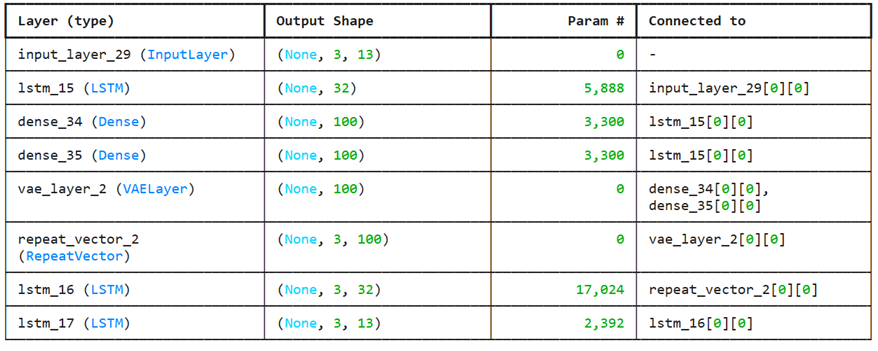

In [92]:
class VAELayer(layers.Layer):
    def __init__(self, **kwargs):
        super(VAELayer, self).__init__(**kwargs)

    def call(self, inputs):
        z_mean, z_log_sigma = inputs
        
        # Calculate KL loss internally to avoid tensor conversion errors
        kl_loss = -0.5 * K.mean(1 + z_log_sigma - K.square(z_mean) - K.exp(z_log_sigma))
        self.add_loss(kl_loss)
        
        # Reparameterization trick
        epsilon = tf.random.normal(shape=(tf.shape(z_mean)[0], latent_dim))
        return z_mean + K.exp(z_log_sigma / 2) * epsilon

# Parameters from example.py
intermediate_dim = 32
latent_dim = 100
batch_size = 1

# --- ENCODER ---
inputs = layers.Input(shape=(timesteps, input_dim,))
h = layers.LSTM(intermediate_dim)(inputs)
z_mean = layers.Dense(latent_dim)(h)
z_log_sigma = layers.Dense(latent_dim)(h)

# Use the custom layer
z = VAELayer()([z_mean, z_log_sigma])

# --- DECODER ---
decoder_h = layers.LSTM(intermediate_dim, return_sequences=True)
decoder_mean = layers.LSTM(input_dim, return_sequences=True)

h_decoded = layers.RepeatVector(timesteps)(z)
h_decoded = decoder_h(h_decoded)
x_decoded_mean = decoder_mean(h_decoded)

# --- MODELS ---
vae = models.Model(inputs, x_decoded_mean)

# The loss function now only needs to handle MSE (KL is added by VAELayer)
vae.compile(optimizer='adam', loss='mse')

# For Inference: Encoder and Generator
encoder = models.Model(inputs, z_mean)

decoder_input = layers.Input(shape=(latent_dim,))
_h_decoded = layers.RepeatVector(timesteps)(decoder_input)
_h_decoded = decoder_h(_h_decoded)
_x_decoded_mean = decoder_mean(_h_decoded)
generator = models.Model(decoder_input, _x_decoded_mean)

print("Model built and compiled successfully.")

Model built and compiled successfully.


In [99]:
vae.summary()

# Encoder summary
encoder.summary()

# Generator (decoder) summary
generator.summary()

Model: "functional_23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_29 (InputLayer)   │ (None, 3, 13)             │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lstm_15 (LSTM)                │ (None, 32)                │           5,888 │ input_layer_29[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_34 (Dense)              │ (None, 100)               │           3,300 │ lstm_15[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_35 (Dense)              │ (None, 100)               │           3,300 │ lstm_15[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ vae_layer_2 (VAELayer)        │ (None, 100)               │               0 │ dense_34[0][0],            │
│                               │                           │                 │ dense_35[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ repeat_vector_2               │ (None, 3, 100)            │               0 │ vae_layer_2[0][0]          │
│ (RepeatVector)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lstm_16 (LSTM)                │ (None, 3, 32)             │          17,024 │ repeat_vector_2[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lstm_17 (LSTM)                │ (None, 3, 13)             │           2,392 │ lstm_16[0][0]              │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 31,904 (124.62 KB)

 Trainable params: 31,904 (124.62 KB)

 Non-trainable params: 0 (0.00 B)

Model: "functional_24"

... (5 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_30 (InputLayer)          │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector_3 (RepeatVector)       │ (None, 3, 100)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_16 (LSTM)                       │ (None, 3, 32)               │          17,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_17 (LSTM)                       │ (None, 3, 13)               │           2,392 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 19,416 (75.84 KB)

 Trainable params: 19,416 (75.84 KB)

 Non-trainable params: 0 (0.00 B)

### Training

In [100]:
vae.fit(x, x, epochs=20, batch_size=batch_size)

Epoch 1/20
415/415 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - loss: 0.1845
Epoch 2/20
415/415 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0627
Epoch 3/20
415/415 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0478
Epoch 4/20
415/415 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0408
Epoch 5/20
415/415 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0350
Epoch 6/20
415/415 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0318
Epoch 7/20
415/415 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0314
Epoch 8/20
415/415 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0311
Epoch 9/20
415/415 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0298
Epoch 10/20
415/415 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0309
Epoch 11/20
415/415 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0296
Epoch 12/20
415/415 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0291
Epoch 13/20
415/415 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0261
Epoch 14/20
415/415 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0305
Epoch 15/20
415/415 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - l

#### Evaluation and Anomaly Detection
Once trained, we use the model to predict (reconstruct) the data.

##### Reconstruction Error: 
The core of this strategy is calculating the Mean Squared Error (MSE) between the input data and the model's output. If a specific sequence follows the rules the LSTM-VAE learned during training, the preds (reconstruction) will be very close to x (input), resulting in a low MSE. If the input contains a pattern never seen before (an anomaly), the VAE will attempt to fix it back to a normal pattern during reconstruction. This creates a large mathematical gap between the input and the output, leading to a high MSE.
	
##### Static Percentile Thresholding: 
The code uses a Percentile-based Threshold to separate normal behavior from anomalies. By choosing the n-th percentile, we are making the assumption that the most unusual n% of our data points are anomalies.es. 


415/415 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Threshold set at: 0.0477
Anomalies detected: 42 sequences


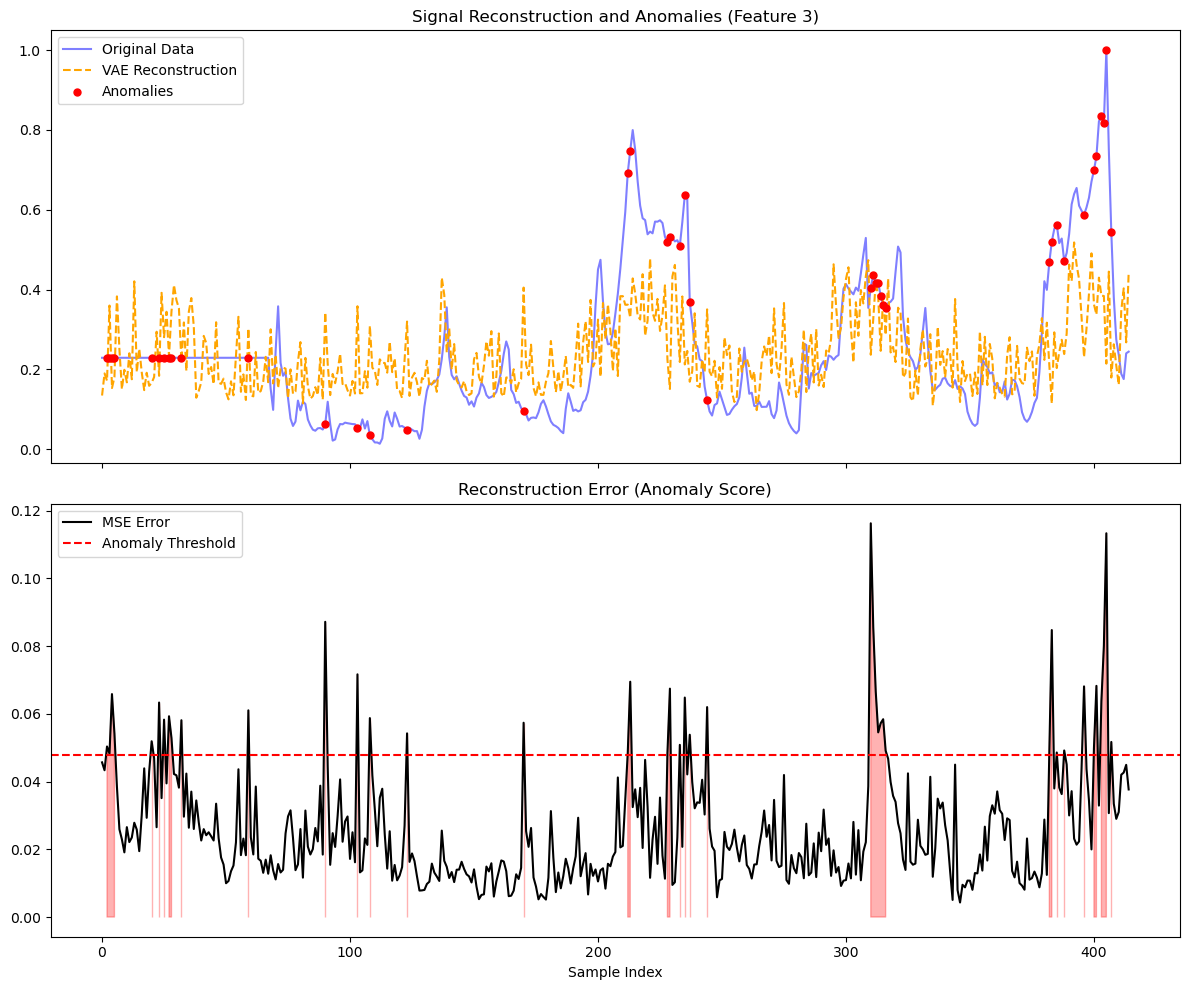

In [102]:
# 1. Generate predictions for the whole dataset
preds = vae.predict(x, batch_size=batch_size)

# 2. Calculate Reconstruction Error (MSE)
# We average the squared difference across timesteps and features
mse_error = np.mean(np.power(x - preds, 2), axis=(1, 2))

# 3. Define the Anomaly Threshold
# Identifying the top 10% highest errors as potential anomalies
threshold = np.percentile(mse_error, 90)
is_anomaly = mse_error > threshold

print(f"Threshold set at: {threshold:.4f}")
print(f"Anomalies detected: {np.sum(is_anomaly)} sequences")

# 4. Plotting the results
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

# Plot A: Signal Reconstruction (Focusing on Feature index 3)
feature_idx = 3 
ax1.plot(x[:, 0, feature_idx], label='Original Data', color='blue', alpha=0.5)
ax1.plot(preds[:, 0, feature_idx], label='VAE Reconstruction', color='orange', linestyle='--')

# Highlight anomalous points with red dots
anomaly_indices = np.where(is_anomaly)[0]
ax1.scatter(anomaly_indices, x[anomaly_indices, 0, feature_idx], 
            color='red', label='Anomalies', s=25, zorder=5)
ax1.set_title(f"Signal Reconstruction and Anomalies (Feature {feature_idx})")
ax1.legend()

# Plot B: Reconstruction Error Level
ax2.plot(mse_error, color='black', label='MSE Error')
ax2.axhline(y=threshold, color='red', linestyle='--', label='Anomaly Threshold')

# Corrected: .fill_between() without the 'set_' prefix
ax2.fill_between(range(len(mse_error)), 0, mse_error, where=is_anomaly, color='red', alpha=0.3)

ax2.set_title("Reconstruction Error (Anomaly Score)")
ax2.set_xlabel("Sample Index")
ax2.legend()

plt.tight_layout()
plt.show()

# Exercise 2: Generating Sentences from a Continuous Space
The objective of this exercise is to transition from numerical data to Natural Language Processing (NLP). We aim to build a generative model capable of "understanding" English sentence structures by mapping them into a continuous latent space. Unlike Exercise 1, which focused on reconstruction for error detection, this exercise focuses on semantic representation and creative generation. By utilizing a Sequence-to-Sequence (Seq2Seq) architecture, the model learns to compress a sentence into a "thought vector" and then expand that vector back into human-readable text.

### Task 1: Importing NLP Libraries and Preprocessing Tools
We begin by importing the specialized tools required for text manipulation. In addition to TensorFlow, we utilize NLTK (Natural Language Toolkit) for tokenization—the process of splitting sentences into individual words and punctuation. This step is critical because, unlike sensor data, text is discrete and requires a vocabulary mapping (ID-to-word and word-to-ID) before it can be converted into numerical tensors.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import nltk
from nltk.tokenize import word_tokenize
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

import tensorflow as tf
import keras
from keras import layers, ops
from keras.layers import Input, LSTM, Dense, Embedding, Bidirectional, Concatenate, Layer
from keras.models import Model

# word_tokenize needs the Punkt models (newer NLTK uses "punkt_tab")
for pkg in ("punkt", "punkt_tab"):
    try:
        nltk.download(pkg, quiet=True)
    except Exception:
        pass

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.18.0 | Keras 3.8.0


### Task 2: Data Loading and Vectorization

We load `fra.txt`, keep only the English part, lowercase it and tokenize it into words. Four special tokens are reserved:

| id | token | role |
|---|---|---|
| 0 | `<pad>` | zero padding (masked out of the loss) |
| 1 | `\t` | start token, the first decoder input |
| 2 | `<unk>` | rare words (seen fewer than `MIN_FREQ` times) and words removed by word dropout |
| 3 | `<end>` | end of sentence |

Each sentence becomes three integer sequences (teacher forcing):

| t | encoder input | decoder input | target |
|---|---|---|---|
| 0 | `i` | `\t` | `i` |
| 1 | `see` | `i` | `see` |
| 2 | `.` | `see` | `.` |
| 3 | `<end>` | `.` | `<end>` |
| 4 | `<pad>` | `<pad>` | `<pad>` |

The model uses integer ids with an `Embedding` layer. This is mathematically the same as multiplying a one-hot vector by a weight matrix, but much cheaper.

Two cleaning steps matter for a generative model:
* **Duplicates are removed.** `fra.txt` lists many English sentences several times, once per French translation; the first 20,000 lines hold about 12,000 unique English sentences.
* **Rare words become `<unk>`.** Almost half of the vocabulary occurs only once. The model cannot learn anything useful about such words, and they enlarge the output layer, so every word seen fewer than `MIN_FREQ` times is replaced by `<unk>`.

In [2]:
PAD, START, UNK, END = "<pad>", "\t", "<unk>", "<end>"
SPECIAL_TOKENS = [PAD, START, UNK, END]          # ids 0, 1, 2, 3


def get_text_data(data_path, num_samples=20000, min_freq=2, dedupe=True):
    # Load English sentences from fra.txt and build integer tensors for teacher forcing.
    with open(data_path, "r", encoding="utf-8") as f:
        lines = f.read().lower().split("\n")

    sentences, seen = [], set()
    for line in lines[: min(num_samples, len(lines) - 1)]:
        if "\t" not in line:
            continue
        english = line.split("\t")[0].strip()
        if dedupe and english in seen:
            continue
        seen.add(english)
        tokens = word_tokenize(english) + [END]
        sentences.append(tokens)

    # Replace rare words by <unk>
    counts = {}
    for s in sentences:
        for t in s:
            counts[t] = counts.get(t, 0) + 1
    rare = {t for t, n in counts.items() if n < min_freq and t not in SPECIAL_TOKENS}
    sentences = [[UNK if t in rare else t for t in s] for s in sentences]
    n_unk = sum(t == UNK for s in sentences for t in s)

    vocab = sorted({t for s in sentences for t in s} - set(SPECIAL_TOKENS))
    id2token = SPECIAL_TOKENS + vocab
    token2id = {t: i for i, t in enumerate(id2token)}
    max_len = max(len(s) for s in sentences)

    n = len(sentences)
    enc_in = np.zeros((n, max_len), dtype="int32")
    dec_in = np.zeros((n, max_len), dtype="int32")
    target = np.zeros((n, max_len), dtype="int32")
    for i, toks in enumerate(sentences):
        ids = [token2id[t] for t in toks]
        enc_in[i, : len(ids)] = ids
        target[i, : len(ids)] = ids
        dec_in[i, 0] = token2id[START]
        dec_in[i, 1 : len(ids)] = ids[:-1]

    n_tok = sum(len(s) for s in sentences)
    print("Number of sentences  :", n)
    print("Vocabulary size      :", len(id2token), f"({len(rare)} rare words mapped to <unk>)")
    print(f"<unk> share of tokens: {100 * n_unk / n_tok:.1f} %")
    print("Max sequence length  :", max_len)
    return dict(sentences=sentences, id2token=id2token, token2id=token2id,
                max_len=max_len, enc_in=enc_in, dec_in=dec_in, target=target)

### Hyperparameter Setting and Tensor Verification

We use the first 20,000 lines of `fra.txt`, about 12,000 unique sentences. With only 3,000 lines (1,720 unique, very short sentences) the model memorises the training set, and "new" samples from the prior are almost all copies of training sentences. The latent space is much smaller than in the first version (32 instead of 191 dimensions), because a very large latent space mostly adds KL cost without adding useful capacity. The batch size is 64; the original `BATCH_SIZE = 1` was never passed to `fit`, which silently used 32.

| parameter | value | meaning |
|---|---|---|
| `EMBED_DIM` | 128 | word-embedding size |
| `HIDDEN_DIM` | 256 | LSTM units (the encoder is bidirectional) |
| `LATENT_DIM` | 32 | size of $z$ |
| `WORD_DROPOUT` | 0.25 | fraction of decoder input words replaced by `<unk>` |
| `NUM_SAMPLES` / `MIN_FREQ` | 20000 / 2 | lines read from `fra.txt`; words seen fewer than 2 times become `<unk>` |
| `KL_WARMUP_EPOCHS` / `KL_ANNEAL_EPOCHS` | 2 / 10 | $\beta = 0$ for 2 epochs, then rises linearly to `BETA_MAX` |
| `FREE_BITS` | 0.25 | KL (nats) per latent dimension that is not penalised: 32 × 0.25 = 8 nats in total. Raise to 0.5 for more exact reconstructions, at the cost of less fluent random samples |
| `EPOCHS` | 40 | about 190 batches per epoch |

In [3]:
# Data
DATA_PATH = "data_lab1/fra.txt"
NUM_SAMPLES = 20000
MIN_FREQ = 2

# Training
BATCH_SIZE = 64
EPOCHS = 40
LEARNING_RATE = 1e-3

# Model
EMBED_DIM = 128
HIDDEN_DIM = 256
LATENT_DIM = 32

# VAE regularisation (anti posterior-collapse)
WORD_DROPOUT = 0.25
KL_WARMUP_EPOCHS = 2
KL_ANNEAL_EPOCHS = 10
BETA_MAX = 1.0
FREE_BITS = 0.25         # 0.25 nats x 32 dims = 8 nats of KL

# Sampling
NUM_SAMPLES_TO_GENERATE = 5

In [4]:
data = get_text_data(DATA_PATH, num_samples=NUM_SAMPLES, min_freq=MIN_FREQ)

enc_in, dec_in, target = data["enc_in"], data["dec_in"], data["target"]
id2token, token2id = data["id2token"], data["token2id"]

VOCAB_SIZE = len(id2token)
MAX_LEN = data["max_len"]
PAD_ID, START_ID, UNK_ID, END_ID = (token2id[t] for t in SPECIAL_TOKENS)

print("Encoder input :", enc_in.shape)
print("Decoder input :", dec_in.shape)
print("Target        :", target.shape)
print("Example       :", data["sentences"][0])

Number of sentences  : 12280
Vocabulary size      : 1898 (1579 rare words mapped to <unk>)
<unk> share of tokens: 2.3 %
Max sequence length  : 8
Encoder input : (12280, 8)
Decoder input : (12280, 8)
Target        : (12280, 8)
Example       : ['go', '.', '<end>']


### Task 3: Reparameterization Layer

$$z = \mu + \sigma \cdot \epsilon, \qquad \sigma = e^{\frac{1}{2}\log\sigma^2}, \quad \epsilon \sim \mathcal{N}(0, I)$$

The KL divergence is not added inside a layer. It is computed in the training step (Task 5), where it can be weighted by $\beta$.

In [5]:
class Sampling(Layer):
    # Reparameterization trick: z = mu + sigma * eps
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.seed_generator = keras.random.SeedGenerator(SEED)

    def call(self, inputs):
        z_mean, z_log_var = inputs
        eps = keras.random.normal(ops.shape(z_mean), seed=self.seed_generator)
        return z_mean + ops.exp(0.5 * z_log_var) * eps


class RepeatToLength(Layer):
    # Copies z to every timestep of the decoder input sequence.
    def call(self, inputs):
        z, ids = inputs
        return tf.tile(tf.expand_dims(z, 1), [1, tf.shape(ids)[1], 1])

### Task 4: Constructing the Seq2Seq LSTM-VAE Architecture

* **Encoder**: Embedding → bidirectional LSTM → two dense heads for $\mu$ and $\log\sigma^2$.
* **Latent-to-state**: $z$ sets the decoder initial hidden and cell states $(h_0, c_0)$.
* **Decoder**: at every step the LSTM receives *[embedding of previous word ; z]*. Because $z$ is present at every step, the decoder can use it easily.
* **Output layer**: a dense layer produces logits over the vocabulary at every timestep (a `Dense` layer on a 3-D tensor is time-distributed automatically).

One decoder model handles both training (whole sequence) and generation (one step at a time), because it takes the LSTM state as an input and returns the updated state.

In [6]:
def build_sentence_vae(vocab_size, embed_dim, hidden_dim, latent_dim):
    embedding = Embedding(vocab_size, embed_dim, mask_zero=True, name="embedding")

    # -------- Encoder --------
    enc_ids = Input(shape=(None,), dtype="int32", name="encoder_ids")
    h = Bidirectional(LSTM(hidden_dim), name="encoder_bilstm")(embedding(enc_ids))
    z_mean = Dense(latent_dim, name="z_mean")(h)
    z_log_var = Dense(latent_dim, name="z_log_var")(h)
    encoder = Model(enc_ids, [z_mean, z_log_var], name="encoder")

    # -------- z -> initial decoder state --------
    z_in = Input(shape=(latent_dim,), name="z")
    h0 = Dense(hidden_dim, activation="tanh", name="z_to_h")(z_in)
    c0 = Dense(hidden_dim, name="z_to_c")(z_in)
    init_state = Model(z_in, [h0, c0], name="z_to_state")

    # -------- Decoder (works for full sequences and single steps) --------
    dec_ids = Input(shape=(None,), dtype="int32", name="decoder_ids")
    dec_z = Input(shape=(latent_dim,), name="decoder_z")
    h_in = Input(shape=(hidden_dim,), name="h_in")
    c_in = Input(shape=(hidden_dim,), name="c_in")

    z_seq = RepeatToLength(name="repeat_z")([dec_z, dec_ids])
    dec_x = Concatenate(name="word_plus_z")([embedding(dec_ids), z_seq])
    seq, h_out, c_out = LSTM(hidden_dim, return_sequences=True, return_state=True,
                             name="decoder_lstm")(dec_x, initial_state=[h_in, c_in])
    logits = Dense(vocab_size, name="vocab_logits")(seq)
    decoder = Model([dec_ids, dec_z, h_in, c_in], [logits, h_out, c_out], name="decoder")

    return encoder, init_state, decoder

In [7]:
class SentenceVAE(keras.Model):
    # Training step: masked reconstruction + annealed, free-bits KL + word dropout.

    def __init__(self, encoder, init_state, decoder, steps_per_epoch, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.init_state = init_state
        self.decoder = decoder
        self.sampling = Sampling()
        self.warmup_steps = float(KL_WARMUP_EPOCHS * steps_per_epoch)
        self.anneal_steps = float(max(1, KL_ANNEAL_EPOCHS * steps_per_epoch))
        self.trackers = {k: keras.metrics.Mean(name=k)
                         for k in ["loss", "recon", "kl", "beta", "acc"]}

    @property
    def metrics(self):
        return list(self.trackers.values())

    def call(self, inputs, training=False):
        enc, dec = inputs
        z_mean, _ = self.encoder(enc, training=training)
        h0, c0 = self.init_state(z_mean)
        logits, _, _ = self.decoder([dec, z_mean, h0, c0], training=training)
        return logits

    def kl_beta(self):
        step = ops.cast(self.optimizer.iterations, "float32")
        return BETA_MAX * ops.clip((step - self.warmup_steps) / self.anneal_steps, 0.0, 1.0)

    def train_step(self, data):
        x_in, tgt = data[0], data[1]
        enc, dec = x_in[0], x_in[1]

        # Word dropout: replace real words (id > END_ID) in the decoder input by <unk>
        drop = tf.random.uniform(tf.shape(dec)) < WORD_DROPOUT
        dec_dropped = tf.where(drop & (dec > END_ID), tf.cast(UNK_ID, dec.dtype), dec)

        with tf.GradientTape() as tape:
            z_mean, z_log_var = self.encoder(enc, training=True)
            z = self.sampling([z_mean, z_log_var])
            h0, c0 = self.init_state(z, training=True)
            logits, _, _ = self.decoder([dec_dropped, z, h0, c0], training=True)

            mask = ops.cast(tgt > 0, "float32")
            ce = keras.losses.sparse_categorical_crossentropy(tgt, logits, from_logits=True)
            recon = ops.mean(ops.sum(ce * mask, axis=1))            # nats per sentence

            kl_dim = -0.5 * (1 + z_log_var - ops.square(z_mean) - ops.exp(z_log_var))
            kl = ops.mean(ops.sum(kl_dim, axis=1))                  # true KL, for logging
            kl_fb = ops.sum(ops.maximum(ops.mean(kl_dim, axis=0), FREE_BITS))

            beta = self.kl_beta()
            loss = recon + beta * kl_fb

        grads = tape.gradient(loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        pred = ops.cast(ops.argmax(logits, axis=-1), tgt.dtype)
        acc = ops.sum(ops.cast(pred == tgt, "float32") * mask) / ops.sum(mask)

        for k, v in dict(loss=loss, recon=recon, kl=kl, beta=beta, acc=acc).items():
            self.trackers[k].update_state(v)
        return {k: t.result() for k, t in self.trackers.items()}

### Task 5: Model Training with Teacher Forcing

During training the decoder receives the true previous word (teacher forcing), with 25 % of the words replaced by `<unk>` (word dropout). Watch the logged values:
* `recon`: reconstruction loss in nats per sentence. It should fall steadily.
* `kl`: KL divergence in nats per sentence. It should **stay above 0**. A value near 0 means posterior collapse.
* `beta`: the KL weight. It is 0 for the first epochs, then rises to 1.
* `acc`: teacher-forced token accuracy on real tokens (padding excluded).

In [8]:
steps_per_epoch = int(np.ceil(len(enc_in) / BATCH_SIZE))

encoder, init_state, decoder = build_sentence_vae(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, LATENT_DIM)
vae = SentenceVAE(encoder, init_state, decoder, steps_per_epoch)
vae.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE, clipnorm=1.0))

encoder.summary()
decoder.summary()

history = vae.fit(
    [enc_in, dec_in], target,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    shuffle=True,
    verbose=2,
)

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ encoder_ids (InputLayer)      │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ embedding (Embedding)         │ (None, None, 128)         │         242,944 │ encoder_ids[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ not_equal (NotEqual)          │ (None, None)              │               0 │ encoder_ids[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ encoder_bilstm                │ (None, 512)               │         788,480 │ embedding[0][0],           │
│ (Bidirectional)               │                           │                 │ not_equal[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ z_mean (Dense)                │ (None, 32)                │          16,416 │ encoder_bilstm[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ z_log_var (Dense)             │ (None, 32)                │          16,416 │ encoder_bilstm[0][0]       │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 1,064,256 (4.06 MB)

 Trainable params: 1,064,256 (4.06 MB)

 Non-trainable params: 0 (0.00 B)

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ decoder_ids (InputLayer)      │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ decoder_z (InputLayer)        │ (None, 32)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ embedding (Embedding)         │ (None, None, 128)         │         242,944 │ decoder_ids[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ repeat_z (RepeatToLength)     │ (None, None, 32)          │               0 │ decoder_z[0][0],           │
│                               │                           │                 │ decoder_ids[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ word_plus_z (Concatenate)     │ (None, None, 160)         │               0 │ embedding[1][0],           │
│                               │                           │                 │ repeat_z[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ h_in (InputLayer)             │ (None, 256)               │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ c_in (InputLayer)             │ (None, 256)               │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ decoder_lstm (LSTM)           │ [(None, None, 256),       │         427,008 │ word_plus_z[0][0],         │
│                               │ (None, 256), (None, 256)] │                 │ h_in[0][0], c_in[0][0]     │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ vocab_logits (Dense)          │ (None, None, 1898)        │         487,786 │ decoder_lstm[0][0]         │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 1,157,738 (4.42 MB)

 Trainable params: 1,157,738 (4.42 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
192/192 - 33s - 171ms/step - acc: 0.3831 - beta: 0.0000e+00 - kl: 721.6108 - loss: 21.3779 - recon: 21.3779
Epoch 2/40
192/192 - 16s - 82ms/step - acc: 0.4939 - beta: 0.0000e+00 - kl: 519.6420 - loss: 15.9852 - recon: 15.9852
Epoch 3/40
192/192 - 21s - 109ms/step - acc: 0.5368 - beta: 0.0497 - kl: 66.8438 - loss: 15.5918 - recon: 14.3061
Epoch 4/40
192/192 - 16s - 84ms/step - acc: 0.5682 - beta: 0.1497 - kl: 12.0475 - loss: 14.9582 - recon: 13.0941
Epoch 5/40
192/192 - 16s - 82ms/step - acc: 0.5896 - beta: 0.2497 - kl: 10.3398 - loss: 14.9063 - recon: 12.1852
Epoch 6/40
192/192 - 16s - 84ms/step - acc: 0.6014 - beta: 0.3497 - kl: 9.5976 - loss: 15.1311 - recon: 11.5780
Epoch 7/40
192/192 - 21s - 108ms/step - acc: 0.6062 - beta: 0.4497 - kl: 9.0026 - loss: 15.4694 - recon: 11.1776
Epoch 8/40
192/192 - 16s - 84ms/step - acc: 0.6125 - beta: 0.5497 - kl: 8.7295 - loss: 15.9392 - recon: 10.8340
Epoch 9/40
192/192 - 21s - 109ms/step - acc: 0.6163 - beta: 0.6497 - kl: 8.5891 - loss

### Task 6: Autoregressive Inference and Decoding Logic

At generation time there is no teacher. The decoder starts from `\t`, predicts a word, feeds that word back in, and repeats until it produces `<end>` or reaches the maximum number of **words**. The function below decodes a whole batch of latent vectors at once. `temperature=0` gives greedy decoding (most likely word); a positive temperature samples, which gives more varied output.

In [9]:
def ids_to_text(ids):
    # Turn a sequence of ids into a readable sentence (stops at <end>).
    words = []
    for i in ids:
        tok = id2token[int(i)]
        if tok == END or tok == PAD:
            break
        if tok == START:
            continue
        words.append(tok)
    return " ".join(words)


def decode_latent(Z, max_words=MAX_LEN + 2, temperature=0.0, allow_unk=True, rng=None):
    # Autoregressively decode a batch of latent vectors Z (B, latent_dim) into id lists.
    # allow_unk=False forbids <unk>, which gives nicer text when generating from the prior.
    rng = rng or np.random.default_rng()
    Z = np.asarray(Z, dtype="float32").reshape(-1, LATENT_DIM)
    B = Z.shape[0]
    Z_t = tf.convert_to_tensor(Z)                      # Keras 3: don't mix numpy and tensors
    h, c = init_state(Z_t, training=False)
    tok = tf.fill((B, 1), START_ID)
    out = np.zeros((B, max_words), dtype="int32")
    finished = np.zeros(B, dtype=bool)

    for t in range(max_words):
        logits, h, c = decoder([tok, Z_t, h, c], training=False)
        logits = ops.convert_to_numpy(logits)[:, -1, :].astype("float64")
        logits[:, [PAD_ID, START_ID]] = -1e9                   # never emit these
        if not allow_unk:
            logits[:, UNK_ID] = -1e9
        if temperature and temperature > 0:
            p = np.exp((logits - logits.max(1, keepdims=True)) / temperature)
            p /= p.sum(1, keepdims=True)
            nxt = np.array([rng.choice(VOCAB_SIZE, p=row) for row in p])
        else:
            nxt = logits.argmax(1)
        nxt[finished] = PAD_ID
        out[:, t] = nxt
        finished |= nxt == END_ID
        if finished.all():
            break
        tok = tf.convert_to_tensor(nxt.reshape(B, 1).astype("int32"))
    return out


def decode(z, temperature=0.0):
    # Decode a single latent vector to a sentence string.
    return ids_to_text(decode_latent(z, temperature=temperature)[0])


def encode(idx, stochastic=False):
    # Encode sentences (indices into the dataset); returns z (mean or a sample).
    m, lv = encoder.predict(enc_in[np.atleast_1d(idx)], verbose=0)
    if stochastic:
        m = m + np.exp(0.5 * lv) * np.random.randn(*m.shape)
    return m


reference = [ids_to_text(t) for t in target]

#### Reconstruction check
Each sentence is encoded to $\mu$ and decoded greedily. Many reconstructions should match the input exactly; the others are usually close neighbours (same structure, one similar word changed). Rare words appear as `<unk>`.

In [10]:
idx = np.random.choice(len(enc_in), 10, replace=False)
recon_ids = decode_latent(encode(idx))
for i, r in zip(idx, recon_ids):
    hyp = ids_to_text(r)
    print(f"{'OK ' if hyp == reference[i] else '   '} {reference[i]:<28} -> {hyp}")

    this is urgent .             -> this is weird .
OK  it 's <unk> .                -> it 's <unk> .
    he 's a dj .                 -> he 's a biologist .
    i often do this .            -> i know to eat .
OK  you lied to me .             -> you lied to me .
OK  who will help me ?           -> who will help me ?
    i drink to relax .           -> i want to drink .
    let 's take a taxi .         -> let 's take a coin .
OK  sit down , tom !             -> sit down , tom !
    he gave me a cold .          -> he gave me a hint .


### Latent Space Interpolation (Semantic Exploration)
We encode two sentences, walk in a straight line between their latent means and decode each point. The ends should reproduce the two sentences, and the points in between should be grammatical sentences that move gradually from one to the other.

In [11]:
for _ in range(NUM_SAMPLES_TO_GENERATE):
    id_from, id_to = np.random.choice(len(enc_in), 2, replace=False)
    z_from, z_to = encode(id_from)[0], encode(id_to)[0]
    alphas = np.linspace(0, 1, 7)
    path = np.stack([(1 - a) * z_from + a * z_to for a in alphas])

    print("==\t", reference[id_from], "==")
    for a, ids in zip(alphas, decode_latent(path)):
        print(f"{1 - a:.2f}\t", ids_to_text(ids))
    print("==\t", reference[id_to], "==\n")

==	 i 'm downstairs . ==
1.00	 i 'm weak .
0.83	 i 'm restless .
0.67	 i 'm not fit .
0.50	 i 'm very busy .
0.33	 this is not true .
0.17	 this is not true .
0.00	 this is not true .
==	 this is not good . ==

==	 <unk> up . ==
1.00	 <unk> up .
0.83	 <unk> up .
0.67	 <unk> 's important .
0.50	 it 's a waste .
0.33	 it 's a waste .
0.17	 it 's a good day .
0.00	 it 's a good day .
==	 it 's a long story . ==

==	 you have my word . ==
1.00	 you have to go .
0.83	 you have to go .
0.67	 i have to go .
0.50	 i did n't see her .
0.33	 i did n't see you .
0.17	 i did n't see you .
0.00	 i did n't see him .
==	 i did it for him . ==

==	 i have children . ==
1.00	 i have <unk> .
0.83	 i have <unk> .
0.67	 i have forgotten .
0.50	 i can drive .
0.33	 i can help you .
0.17	 i 'll help you .
0.00	 i 'll help you .
==	 i can help tom . ==

==	 stop screaming . ==
1.00	 stop yelling .
0.83	 stop yelling .
0.67	 i 'm <unk> .
0.50	 i feel lonely .
0.33	 i feel good .
0.17	 i feel good .
0.00	 i fe

### Generating New Sentences from the Prior
Because the latent space is regularised towards $\mathcal{N}(0, I)$, we can sample $z \sim \mathcal{N}(0, I)$ and decode it into a new sentence (here `<unk>` is not allowed). The first column shows whether the sentence already exists in the training set (`seen`) or is new (`NEW`).

In [12]:
train_set = set(reference)
Z_prior = np.random.randn(15, LATENT_DIM)
for ids in decode_latent(Z_prior, allow_unk=False):
    s = ids_to_text(ids)
    print(f"{'seen' if s in train_set else 'NEW':>4}  {s}")

print("\nWith temperature 0.7 (more variety):")
for ids in decode_latent(Z_prior, temperature=0.7, allow_unk=False):
    s = ids_to_text(ids)
    print(f"{'seen' if s in train_set else 'NEW':>4}  {s}")

seen  no one loves war .
 NEW  is this seat ?
seen  should i come ?
seen  he is cranky .
seen  that 's my money .
 NEW  that 's new .
seen  you 're upset .
 NEW  here i ask .
 NEW  i got a lot .
seen  i need a bath .
 NEW  i 'm lost .
seen  it 's all mine .
 NEW  i 'll take this .
seen  i screamed .
 NEW  i 'm in jobs .

With temperature 0.7 (more variety):
 NEW  the bill is home .
 NEW  is this seat true ?
seen  we must obey .
seen  he is reading .
seen  that 's possible .
 NEW  i 'm my teacher .
seen  you 're cheating .
 NEW  it 's love .
 NEW  i 'm a bit sick .
seen  i need a bath .
 NEW  i 'm lost .
 NEW  it can help me .
 NEW  i 'll check my way .
seen  tom helped .
 NEW  shut off .


#### Novelty and the temperature trade-off
How generative is the model? We decode 500 random latent vectors at several temperatures and measure:
* **novel**: share of samples that are *not* sentences from the training set,
* **distinct**: share of samples that are different from each other.

At temperature 0 (greedy) the model mostly produces familiar sentences. Higher temperatures give more novel and more varied sentences, but grammar and meaning gradually get worse. Read the examples, not only the numbers.

In [13]:
Z_eval = np.random.randn(500, LATENT_DIM)
rng = np.random.default_rng(SEED)
for temp in [0.0, 0.5, 0.8, 1.0]:
    samples = [ids_to_text(r) for r in decode_latent(Z_eval, temperature=temp,
                                                     allow_unk=False, rng=rng)]
    novel = np.mean([s not in train_set for s in samples])
    distinct = len(set(samples)) / len(samples)
    new_examples = [s for s in dict.fromkeys(samples) if s not in train_set][:4]
    print(f"temperature {temp:.1f}:  novel {100 * novel:5.1f} %   distinct {100 * distinct:5.1f} %")
    for s in new_examples:
        print("      NEW ", s)
    print()

temperature 0.0:  novel  36.0 %   distinct  90.0 %
      NEW  i got in charge .
      NEW  that 's time .
      NEW  do you yourself ?
      NEW  i 'm not .

temperature 0.5:  novel  48.0 %   distinct  98.6 %
      NEW  i got at school .
      NEW  where can do this ?
      NEW  what 's the party ?
      NEW  do you yourself ?

temperature 0.8:  novel  62.0 %   distinct  99.0 %
      NEW  i 'm in charge .
      NEW  where can we eat ?
      NEW  let me continue .
      NEW  what 's cross this ?

temperature 1.0:  novel  73.2 %   distinct  99.0 %
      NEW  i joined her train .
      NEW  did you eat pork ?
      NEW  nothing 's new .
      NEW  what month is all ?



### Task 7: BLEU Score and Edit Distance Evaluation

Reference and hypothesis are now built the same way (words joined by spaces, stopping at `<end>`). We report:
* **Word BLEU-2** and **character BLEU-2**,
* **exact-match rate** (whole sentence correct),
* **normalised word edit distance** = edit distance / reference length (0 is perfect),

for **deterministic** reconstruction ($z = \mu$) and **stochastic** reconstruction ($z = \mu + \sigma\epsilon$).

In [14]:
smooth = SmoothingFunction().method1
BLEU2 = (0.5, 0.5, 0.0, 0.0)


def edit_distance(a, b):
    # Levenshtein distance between two token lists.
    prev = list(range(len(b) + 1))
    for i, ta in enumerate(a, 1):
        cur = [i]
        for j, tb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ta != tb)))
        prev = cur
    return prev[-1]


def score_pair(ref, hyp):
    r, h = ref.split(), hyp.split()
    word_bleu = sentence_bleu([r], h, weights=BLEU2, smoothing_function=smooth) if h else 0.0
    char_bleu = (sentence_bleu([list(ref)], list(hyp), weights=BLEU2, smoothing_function=smooth)
                 if len(hyp) > 1 else 0.0)
    ned = edit_distance(r, h) / max(len(r), 1)
    return word_bleu, char_bleu, float(ref == hyp), ned


def evaluate_reconstruction(num_samples=500, stochastic=False, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(enc_in), min(num_samples, len(enc_in)), replace=False)
    hyps = [ids_to_text(r) for r in decode_latent(encode(idx, stochastic=stochastic))]
    scores = np.array([score_pair(reference[i], h) for i, h in zip(idx, hyps)])
    return dict(zip(["word BLEU-2", "char BLEU-2", "exact match", "norm. edit dist"],
                    scores.mean(0)))


for name, stoch in [("Deterministic (z = mu)", False), ("Stochastic (z ~ q(z|x))", True)]:
    res = evaluate_reconstruction(stochastic=stoch)
    print(f"{name:<26}" + "  ".join(f"{k}: {v:.3f}" for k, v in res.items()))

Deterministic (z = mu)    word BLEU-2: 0.601  char BLEU-2: 0.711  exact match: 0.278  norm. edit dist: 0.236
Stochastic (z ~ q(z|x))   word BLEU-2: 0.348  char BLEU-2: 0.534  exact match: 0.068  norm. edit dist: 0.449


### Token Accuracy
Teacher-forced accuracy of the next-word prediction, computed **only over real tokens** (padding excluded), using $z = \mu$.

In [15]:
correct, total = 0, 0
for s in range(0, len(enc_in), 1024):             # in chunks: full logits would need ~1 GB
    sl = slice(s, s + 1024)
    pred = vae.predict([enc_in[sl], dec_in[sl]], batch_size=256, verbose=0).argmax(-1)
    mask = target[sl] > 0
    correct += (pred == target[sl])[mask].sum()
    total += mask.sum()
print(f"Token accuracy (non-padding): {correct / total:.4f}")

Token accuracy (non-padding): 0.8429


### Task 8: Convergence Diagnostics and Latent Histograms
* **Loss curves**: reconstruction and KL per epoch. The KL weight $\beta$ is shown on a second axis.
* **Active units** (Burda et al., 2016): a latent dimension is *active* if its mean $\mu_d$ changes across sentences ($\mathrm{Var}_x[\mu_d] > 0.01$). With posterior collapse this count is 0.
* **Histograms** of latent means and standard deviations. Active dimensions have $\sigma \ll 1$; dimensions with $\sigma \approx 1$ are unused.

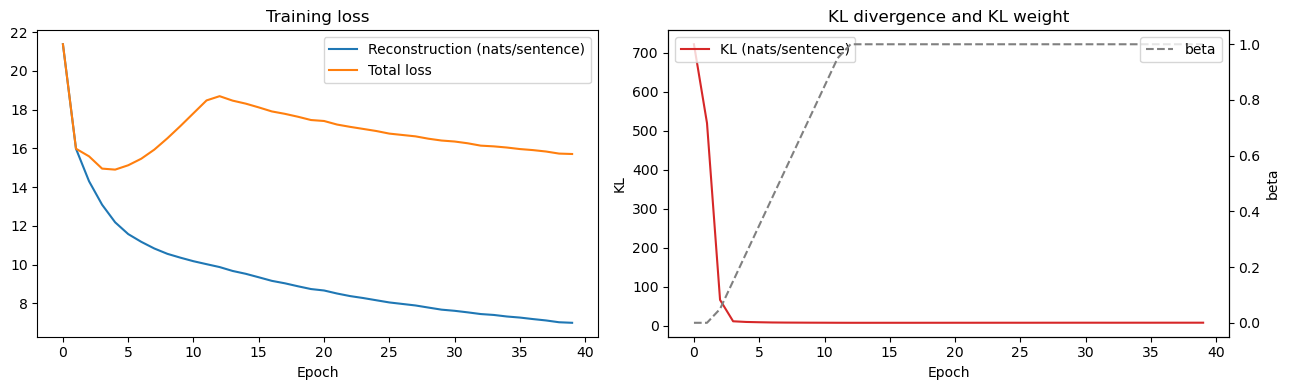

In [16]:
hist = history.history
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(hist["recon"], label="Reconstruction (nats/sentence)")
ax[0].plot(hist["loss"], label="Total loss")
ax[0].set_xlabel("Epoch"); ax[0].set_title("Training loss"); ax[0].legend()

ax[1].plot(hist["kl"], color="tab:red", label="KL (nats/sentence)")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("KL"); ax[1].set_title("KL divergence and KL weight")
ax2 = ax[1].twinx()
ax2.plot(hist["beta"], color="gray", ls="--", label="beta")
ax2.set_ylabel("beta")
ax[1].legend(loc="upper left"); ax2.legend(loc="upper right")
plt.tight_layout(); plt.show()

Active latent units: 32 / 32
Mean KL per sentence: 8.00 nats


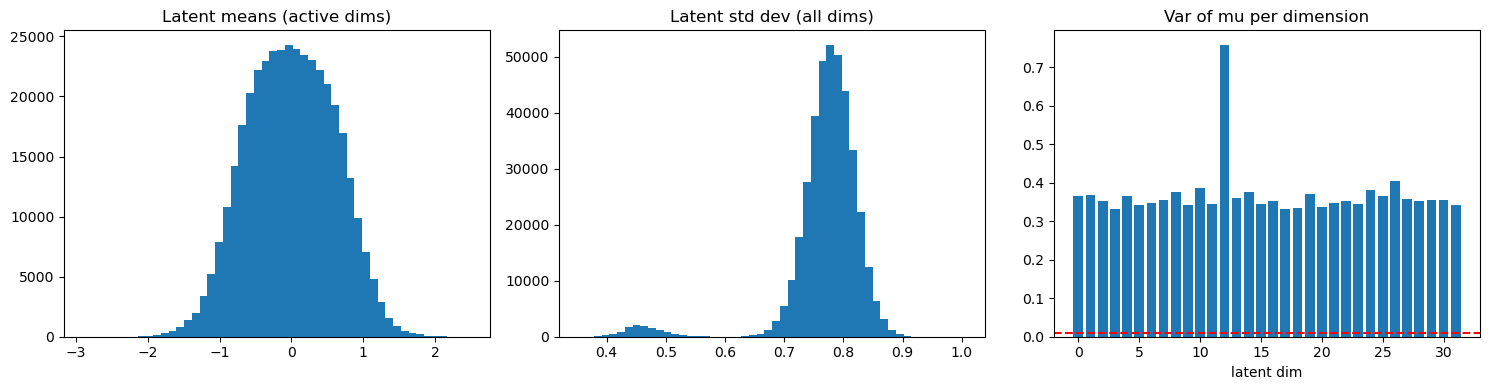

In [17]:
z_mean_all, z_log_var_all = encoder.predict(enc_in, batch_size=256, verbose=0)
var_of_means = z_mean_all.var(axis=0)
active = var_of_means > 0.01
print(f"Active latent units: {active.sum()} / {LATENT_DIM}")

kl_per_sentence = -0.5 * np.sum(1 + z_log_var_all - z_mean_all**2 - np.exp(z_log_var_all), axis=1)
print(f"Mean KL per sentence: {kl_per_sentence.mean():.2f} nats")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(z_mean_all[:, active].flatten(), bins=50)
ax[0].set_title("Latent means (active dims)")
ax[1].hist(np.exp(0.5 * z_log_var_all).flatten(), bins=50)
ax[1].set_title("Latent std dev (all dims)")
ax[2].bar(range(LATENT_DIM), var_of_means)
ax[2].axhline(0.01, color="red", ls="--")
ax[2].set_title("Var of mu per dimension"); ax[2].set_xlabel("latent dim")
plt.tight_layout(); plt.show()

### Latent Traversal
We change one latent dimension at a time around the encoding of a sentence. We use the **most active** dimensions; inactive dimensions would not change the output.

In [18]:
def latent_traversal(z_base, dim, values):
    Z = np.repeat(z_base[None, :], len(values), axis=0)
    Z[:, dim] = values
    for v, ids in zip(values, decode_latent(Z)):
        print(f"z[{dim}] = {v:+.2f} -> {ids_to_text(ids)}")


z0 = encode(0)[0]
print("Base sentence:", reference[0], "\n")
top_dims = np.argsort(var_of_means)[::-1][:2]
spread = np.sqrt(var_of_means[top_dims[0]])
for d in top_dims:
    latent_traversal(z0, d, z0[d] + spread * np.linspace(-3, 3, 7))
    print()

Base sentence: go . 

z[12] = -1.11 -> i like to go .
z[12] = -0.24 -> go to bed .
z[12] = +0.63 -> go away .
z[12] = +1.51 -> go inside .
z[12] = +2.38 -> go .
z[12] = +3.25 -> jump .
z[12] = +4.12 -> jump .

z[26] = -3.63 -> go inside .
z[26] = -2.76 -> go inside .
z[26] = -1.89 -> go inside .
z[26] = -1.02 -> go inside .
z[26] = -0.15 -> go inside .
z[26] = +0.72 -> go inside .
z[26] = +1.59 -> go inside .

